In [1]:
import sys
print(sys.prefix)
print(sys.version)

C:\Users\Lereiya03.DESKTOP-AO7QHNT\AppData\Local\uv\cache\builds-v0\.tmpb2IYDx
3.12.15 (main, Oct 14 2026, 01:08:45) [MSC v.1944 64 bit (AMD64)]


In [2]:
import numpy, pandas, sklearn, matplotlib, yfinance
print("numpy", numpy.__version__)
print("pandas", pandas.__version__)
print("sklearn", sklearn.__version__)
print("yfinance", yfinance.__version__)

numpy 2.5.4
pandas 3.0.6
sklearn 1.9.1
yfinance 1.7.0


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

features = pd.read_parquet("../data/processed/features.parquet")
features["date"] = pd.to_datetime(features["date"])

print(f"Rows: {len(features):,}")
print(f"Stocks: {features['ticker'].nunique()}")
print(f"Date range: {features['date'].min().date()} → {features['date'].max().date()}")
features[["date", "ticker", "close", "target"]].head()

Rows: 173,575
Stocks: 50
Date range: 2010-02-02 → 2023-12-28


,date,ticker,close,target
20,2010-02-02,AAPL,5.858099,0.017060
21,2010-02-03,AAPL,5.958896,-0.036704
22,2010-02-04,AAPL,5.744146,0.017600
23,2010-02-05,AAPL,5.846137,-0.006879
24,2010-02-08,AAPL,5.806057,0.010607


In [4]:
import pandas as pd
import numpy as np
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score

# 1. Load data
features = pd.read_parquet("../data/processed/features.parquet")
features["date"] = pd.to_datetime(features["date"])

# 2. Define features and chronological splits
FEATURE_COLS = [
    "ret_lag_1", "ret_lag_2", "ret_lag_5", "ret_lag_10", "ret_lag_20",
    "vol_5", "vol_10", "vol_20",
    "rsi_14", "macd", "bb_position", "vol_ratio",
]

train = features[features["date"] <= "2019-12-31"]
val = features[(features["date"] > "2019-12-31") & (features["date"] <= "2021-12-31")]
test = features[features["date"] > "2021-12-31"]

X_train, y_train = train[FEATURE_COLS].values, train["target"].values
X_val, y_val = val[FEATURE_COLS].values, val["target"].values
X_test, y_test = test[FEATURE_COLS].values, test["target"].values

print(f"Train size: {len(X_train):,} | Val size: {len(X_val):,} | Test size: {len(X_test):,}")

# 3. Scale features (Fit on Train ONLY to prevent data leakage)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# 4. Train Ridge Regression
model = Ridge(alpha=10.0)
model.fit(X_train_scaled, y_train)

# 5. Evaluate on the Test set
y_pred = model.predict(X_test_scaled)

# Calculate Metrics
mse = np.mean((y_test - y_pred) ** 2)
r2 = r2_score(y_test, y_pred)
hit_rate = np.mean(np.sign(y_test) == np.sign(y_pred))

print("\n--- Test Set Results ---")
print(f"MSE: {mse:.6e}")
print(f"R²: {r2:.5f}")
print(f"Hit Rate (Direction Accuracy): {hit_rate:.2%}")

Train size: 123,325 | Val size: 25,250 | Test size: 25,000

--- Test Set Results ---
MSE: 4.177742e-04
R²: -0.00404
Hit Rate (Direction Accuracy): 50.58%


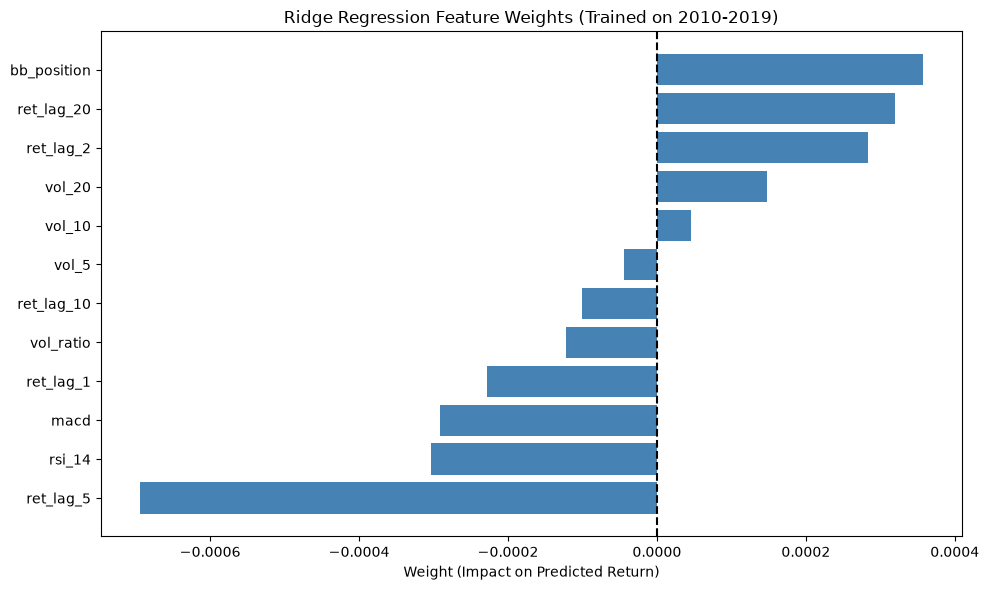

In [5]:
import matplotlib.pyplot as plt

# Get feature weights
weights = model.coef_

# Create a DataFrame for easy plotting
importance = pd.DataFrame({
    "Feature": FEATURE_COLS,
    "Weight": weights
}).sort_values(by="Weight", ascending=True)

# Plot
plt.figure(figsize=(10, 6))
plt.barh(importance["Feature"], importance["Weight"], color="steelblue")
plt.axvline(0, color="black", linestyle="--")
plt.title("Ridge Regression Feature Weights (Trained on 2010-2019)")
plt.xlabel("Weight (Impact on Predicted Return)")
plt.tight_layout()
plt.show()

In [6]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

# 1. Prepare PyTorch Data
X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32)
X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32)

train_dataset = TensorDataset(X_train_t, y_train_t)
train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True)

# 2. Define the MLP Architecture
class StockMLP(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(32, 1)
        )
    def forward(self, x):
        return self.net(x).squeeze(-1)

model_nn = StockMLP(input_dim=len(FEATURE_COLS))
criterion = nn.MSELoss()
optimizer = optim.Adam(model_nn.parameters(), lr=0.001, weight_decay=1e-4)

# 3. Train the Model
epochs = 10
print("Training Neural Network...")
for epoch in range(epochs):
    model_nn.train()
    total_loss = 0
    for batch_X, batch_y in train_loader:
        optimizer.zero_grad()
        outputs = model_nn(batch_X)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    print(f"Epoch {epoch+1}/{epochs} - Loss: {total_loss/len(train_loader):.6f}")

# 4. Evaluate
model_nn.eval()
with torch.no_grad():
    y_pred_nn = model_nn(X_test_t).numpy()

r2_nn = r2_score(y_test, y_pred_nn)
hit_rate_nn = np.mean(np.sign(y_test) == np.sign(y_pred_nn))

print("\n--- Neural Network Test Results ---")
print(f"R²: {r2_nn:.5f}")
print(f"Hit Rate: {hit_rate_nn:.2%}")

Training Neural Network...
Epoch 1/10 - Loss: 0.001943
Epoch 2/10 - Loss: 0.000298
Epoch 3/10 - Loss: 0.000280
Epoch 4/10 - Loss: 0.000279
Epoch 5/10 - Loss: 0.000278
Epoch 6/10 - Loss: 0.000278
Epoch 7/10 - Loss: 0.000278
Epoch 8/10 - Loss: 0.000278
Epoch 9/10 - Loss: 0.000278
Epoch 10/10 - Loss: 0.000278

--- Neural Network Test Results ---
R²: -0.00003
Hit Rate: 51.34%


In [7]:
import torch
print(torch.__version__)

2.8.0+cpu
